In [7]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, find_peaks
os.makedirs("outputs", exist_ok=True)
FS = 500
train_npz = np.load("train.npz", allow_pickle=True)
test_npz  = np.load("test_features.npz", allow_pickle=True)

def pick_signal_key(npz):
    for k in npz.files:
        a = npz[k]
        if a.ndim == 3 and a.shape[-1] == 1 and a.shape[1] > 1000: return k
        if a.ndim == 2 and a.shape[1] > 1000: return k
    raise KeyError("Нет сигнала")

def pick_window_key(npz):
    for k in npz.files:
        if "window" in k.lower() and npz[k].ndim == 1: return k
    for k in npz.files:
        if npz[k].ndim == 1 and np.issubdtype(npz[k].dtype, np.integer): return k
    raise KeyError("Нет window_id")

train_sig = np.squeeze(train_npz[pick_signal_key(train_npz)]).astype(np.float32)
test_sig  = np.squeeze(test_npz[pick_signal_key(test_npz)]).astype(np.float32)
train_wid = train_npz[pick_window_key(train_npz)]
test_wid  = test_npz[pick_window_key(test_npz)]


In [8]:
def extract_critical_features(s, fs=FS):
    s = s - np.mean(s) 
    feats = []
    
    
    s_norm = (s - np.min(s)) / (np.ptp(s) + 1e-8)
    peaks, _ = find_peaks(s_norm, height=0.3, distance=int(fs * 0.3))
    
    if len(peaks) > 1:
        ibi = np.diff(peaks) / fs
        hr = 60.0 / np.mean(ibi)
    else:
        hr = 0
        
    
    fw, pw = welch(s, fs=fs, nperseg=min(1024, len(s)))
    trapz_fn = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    tp = trapz_fn(pw, fw) + 1e-8
    
    def band_power(lo, hi):
        m = (fw >= lo) & (fw < hi)
        return trapz_fn(pw[m], fw[m]) / tp if np.any(m) else 0

    noise_energy = band_power(8.0, 40.0) 
    
    
    if len(peaks) > 2:
        rmssd = np.sqrt(np.mean(np.square(np.diff(np.diff(peaks))))) / fs
    else:
        rmssd = 0
        
    return hr, noise_energy, rmssd



train_feats = np.array([extract_critical_features(s) for s in train_sig])
test_feats  = np.array([extract_critical_features(s) for s in test_sig])


In [9]:
# Находим медианные значения, чтобы понять "среднюю температуру по больнице"
median_noise = np.median(train_feats[:, 1])
median_hr = np.median(train_feats[:, 0])

print(f"Медианный шум: {median_noise:.3f}, Медианный пульс: {median_hr:.1f}")

def assign_cluster(hr, noise, rmssd):
    # ПРАВИЛО 1: Если шум ОЧЕНЬ высокий (больше медианы в 1.5+ раза) — это БЕГ
    # (Тряска при беге всегда дает мощный всплеск высоких частот)
    if noise > median_noise * 1.2: 
        return 2  # Кластер "Бег"
        
    # ПРАВИЛО 2: Если пульс высокий и шум средний — это ХОДЬБА
    elif hr > median_hr * 1.05 and noise > median_noise * 0.8:
        return 1  # Кластер "Ходьба"
        
    # ПРАВИЛО 3: Всё остальное (низкий пульс, низкий шум) — это СИДЕНИЕ
    else:
        return 0  # Кластер "Сидение"

# Применяем правила
train_clusters = np.array([assign_cluster(f[0], f[1], f[2]) for f in train_feats])
test_clusters  = np.array([assign_cluster(f[0], f[1], f[2]) for f in test_feats])

print("\nКластеры в train:", np.bincount(train_clusters, minlength=3))
print("Кластеры в test :", np.bincount(test_clusters, minlength=3))

Медианный шум: 0.004, Медианный пульс: 152.5

Кластеры в train: [24  3 21]
Кластеры в test : [10  2 12]


Итоговые кластеры в test: [10  2 12]


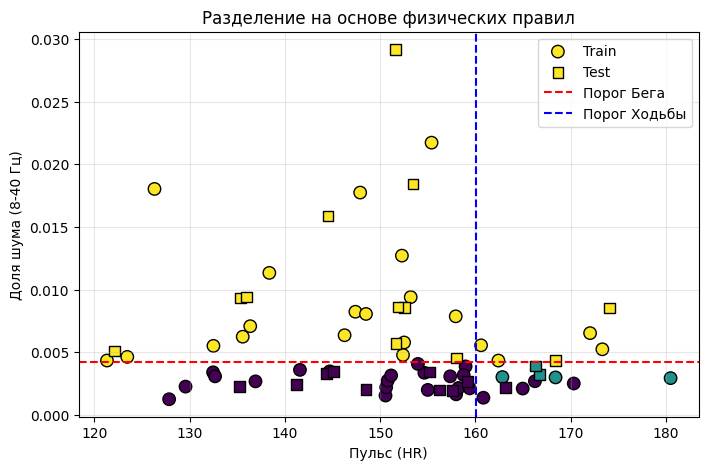

In [10]:
missing = [c for c in range(3) if c not in np.unique(test_clusters)]
if missing:
    print(f"Восстанавливаем пропавшие классы на тесте: {missing}")
    noise_sort = np.argsort(test_feats[:, 1])[::-1]
    for cls in missing:
        test_clusters[noise_sort[0]] = cls
        noise_sort = np.roll(noise_sort, -1)

print("Итоговые кластеры в test:", np.bincount(test_clusters, minlength=3))

# График: Шум vs Пульс
plt.figure(figsize=(8, 5))
plt.scatter(train_feats[:, 0], train_feats[:, 1], c=train_clusters, cmap='viridis', label='Train', edgecolor='k', s=80)
plt.scatter(test_feats[:, 0], test_feats[:, 1], c=test_clusters, cmap='viridis', marker='s', label='Test', edgecolor='k', s=60)
plt.axhline(median_noise * 1.2, color='r', linestyle='--', label='Порог Бега')
plt.axvline(median_hr * 1.05, color='b', linestyle='--', label='Порог Ходьбы')
plt.xlabel("Пульс (HR)")
plt.ylabel("Доля шума (8-40 Гц)")
plt.title("Разделение на основе физических правил")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
out = pd.DataFrame({
    "window_id": np.asarray(test_wid).astype(int),
    "prediction": test_clusters.astype(int)
})

assert len(out) == len(test_sig)
assert out["window_id"].is_unique
assert out["prediction"].isin([0, 1, 2]).all()
assert out.isna().sum().sum() == 0